# EDM on CIFAR-10: conditioning, CFG and FID

In this notebook you generate CIFAR-10 images with NVIDIA's pretrained EDM models (Karras et al., 2022) and measure
them (parts 1–5). Then you train EDM's network yourself, for CFG (part 6).

## Checkpoint assignment, due Friday, November 6

Everything in this notebook is part of it.

**In the next 24 hours**
- Create your public GitHub repository. Give it a README with the setup, the data downloads and the command
  behind each figure and table, and add a notes file.
- Get this notebook running on a GPU: the downloads and parts 1–3 take a few minutes.

**This week: generation and sampling (parts 1–5)**
- the sample grids
- the trajectory figures, with your answers to part 3's questions
- part 5's table and plots of accuracy, FID and FID_class against $w$, at 1,000 images

**By the checkpoint: training (the rest)**
- Part 6: FID across snapshots for 100 and 1,000 training images, samples next to their nearest training images,
  and the CFG grids.
- An MNIST CFG network, trained with the MNIST guidance lab: label accuracy and FID for each $w$.
- Encouraged: an actual training run of EDM's full network on all 50,000 images, on a DSMLP GPU for as many
  hours as you can (the end of part 6). Show its loss curve and FID across snapshots.

**Submit by Friday, November 6**
- **Required by the course:** a report with the title, the abstract and the introduction (the problem, related
  work and your data), and a link to your repository.
- **Also asked by us:** a short preliminary-results section in the report, with this week's figures and tables,
  each with a sentence on what it shows. Your README should reproduce each one.

Full submission instructions and grading details: the
[official Q1 assignment](https://dsc-capstone.org/2026-27/assignments/projects/q1/).

## The notebook

1. Unconditional samples, and inside the sampler: the noisy image and the denoiser's estimate at each step
2. Conditional samples
3. CFG with two networks, and your trajectory figures with a condition
4. Measuring: label accuracy and FID
5. The CFG sweep: accuracy and FID for w = 0, 1, 1.5, 2, 3, 4
6. Training EDM's network on 100 and 1,000 images, with CFG (more training data is optional)

**Run it on a GPU,** on DSMLP or Colab. On Colab, if the first cell prints `cpu`, choose Runtime → Change runtime
type and pick a GPU. On an NVIDIA GPU, `QUICK` is `False`: part 5 generates 1,000 images
for each value of $w$, and part 6 trains for 20,000 updates per training set. Each long step prints how long it
will take. On a laptop, `QUICK` is `True` and every step is cut down far enough to test the code, not to give
results. The first run downloads about 720 MB into `downloads/`. Generated images are saved in `outputs/`, so a
rerun reuses them.

**Notation.** As in the course, $x_1$ is a clean image and $x_0$ is Gaussian noise. For the network we use EDM's
letter $D$, as EDM's paper and code do: EDM's networks return `D_x`, the clean-image estimate
(`training/networks.py`).
- A noisy image is $x = x_1 + \sigma x_0$. This is the slides' $y = x_t/\alpha_t$, and the noise level $\sigma$
  is the slides' $\rho = \sigma_t/\alpha_t$.
- The network's estimate of the clean image is $D(x;\sigma,c)$ for class $c$, the slides' $\hat x_1(c)$. With
  no class it is $D(x;\sigma)$, the slides' $\hat x_1(\varnothing)$.
- On the noise-alignment slides, $D(y;\rho)$ is the PCA denoiser. It takes the same inputs and also returns a
  clean-image estimate.

In [1]:
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # before torch: Apple GPUs fall back to CPU
import copy, hashlib, io, json, pickle, shutil, sys, tarfile, time, types, urllib.request, zipfile
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

if os.environ.get("LAB_DEVICE"):
    DEVICE = torch.device(os.environ["LAB_DEVICE"])
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
QUICK = DEVICE.type != "cuda"                    # True keeps laptop runs short; set False on a GPU
N_EVAL = int(os.environ.get("LAB_N_EVAL", 200 if QUICK else 1000))   # images per setting in part 5
BATCH = 100 if QUICK else 500                    # images per sampling batch
print(f"device {DEVICE}, QUICK = {QUICK}, {N_EVAL} images per setting")

device cuda, QUICK = False, 1000 images per setting


### Downloads
Each file is checked against its SHA-256 checksum, so a broken download is caught, and an interrupted download
resumes when you rerun the cell. CIFAR-10 comes from Hugging Face's copy (`uoft-cs/cifar10`), which downloads
much faster than the original server in Toronto. If you already have the original `cifar-10-python.tar.gz`, or
EDM's files from its README, copy them into `downloads/` and they are used instead. To use your own clone of EDM,
set the environment variable `EDM_DIR` to its folder.

In [2]:
DL, OUT = Path("downloads"), Path("outputs")
DL.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
EDM_COMMIT = "008a4e5316c8e3bfe61a62f874bddba254295afb"   # the NVlabs/edm version this notebook was tested with
NV = "https://nvlabs-fi-cdn.nvidia.com/edm"
FILES = {   # file: (address, SHA-256)
    "edm-cifar10-32x32-uncond-vp.pkl": (f"{NV}/pretrained/edm-cifar10-32x32-uncond-vp.pkl",
                                        "4d5dcc1f1d0d41c8934ad21626eeddbdc0460182becf9fc059a0631b1eedb4da"),
    "edm-cifar10-32x32-cond-vp.pkl": (f"{NV}/pretrained/edm-cifar10-32x32-cond-vp.pkl",
                                      "b27385e4f2f8d4d1e2e2c03864c5a9574a0c58ba81eb11625ae6d15c401f4796"),
    "cifar10-32x32.npz": (f"{NV}/fid-refs/cifar10-32x32.npz",
                          "4ada108cdfd8e43409ed427f5f76631beac9b9617cdcaf416d41b1e161d85969"),
    "inception-2015-12-05.pkl": ("https://api.ngc.nvidia.com/v2/models/nvidia/research/stylegan3/versions/1/"
                                 "files/metrics/inception-2015-12-05.pkl",
                                 "a31bd1d4522101109044ec28621a5fcb591ed6115e0d58104fc013fa01ef94f7"),
    "cifar10_resnet56-187c023a.pt": ("https://github.com/chenyaofo/pytorch-cifar-models/releases/download/resnet/"
                                     "cifar10_resnet56-187c023a.pt",
                                     "187c023aee0c9cf3093a682d9447a538cbaf5489f7ae78a7df4edf2246ce380b"),
}
TAR = DL / "cifar-10-python.tar.gz"     # the original CIFAR-10 archive: used if you already have it
if not TAR.exists():                    # otherwise Hugging Face's copy of the same images, a fixed version
    HF = "https://huggingface.co/datasets/uoft-cs/cifar10/resolve/0b2714987fa478483af9968de7c934580d0bb9a2/plain_text"
    FILES["cifar10-train.parquet"] = (f"{HF}/train-00000-of-00001.parquet",
                                      "8428b53a88a11ac374111006708df51469e315a22ac6d66470afd9c78d2ae883")
    FILES["cifar10-test.parquet"] = (f"{HF}/test-00000-of-00001.parquet",
                                     "841389e6f2d64f28bf17310e430aebac20ec3ba611a3c5e231dc93c645ce84de")


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


def download(url, path, attempts=8):
    """Download with retries; an interrupted download resumes where it stopped."""
    part = Path(f"{path}.part")
    for _ in range(attempts):
        done = part.stat().st_size if part.exists() else 0
        request = urllib.request.Request(url, headers={"Range": f"bytes={done}-"} if done else {})
        try:
            with urllib.request.urlopen(request, timeout=60) as r, open(part, "ab" if r.status == 206 else "wb") as f:
                shutil.copyfileobj(r, f, 1 << 20)
            break
        except urllib.error.HTTPError as e:
            if e.code == 416:                    # the partial file is already complete
                break
            print(f"  {e}; retrying", flush=True)
        except OSError as e:                     # a timeout or a dropped connection
            print(f"  {e}; retrying", flush=True)
    else:
        raise RuntimeError(f"could not download {url}; run this cell again to resume")
    part.replace(path)


for name, (url, digest) in FILES.items():
    path = DL / name
    if path.exists() and sha256(path) == digest:
        continue
    print("downloading", name, flush=True)
    download(url, path)
    if sha256(path) != digest:
        path.unlink()
        raise RuntimeError(f"{name}: the checksum does not match; run this cell again")

EDM_DIR = Path(os.environ.get("EDM_DIR", DL / f"edm-{EDM_COMMIT}"))
if not EDM_DIR.exists():
    print("downloading EDM's code", flush=True)
    download(f"https://github.com/NVlabs/edm/archive/{EDM_COMMIT}.zip", DL / "edm.zip")
    with zipfile.ZipFile(DL / "edm.zip") as z:
        z.extractall(DL)
sampler_file = EDM_DIR / "torch_utils" / "misc.py"   # EDM's training sampler needs a one-line fix for PyTorch 2.2+
if "super().__init__(dataset)" in sampler_file.read_text():
    if "EDM_DIR" in os.environ:                      # your own clone: we do not edit it for you
        print(f"For train.py with PyTorch 2.2 or later, change super().__init__(dataset) to super().__init__() "
              f"in {sampler_file}")
    else:
        sampler_file.write_text(sampler_file.read_text().replace("super().__init__(dataset)", "super().__init__()"))
try:
    import distutils.util                        # EDM imports one helper from distutils, removed in Python 3.12
except ImportError:
    shim = types.ModuleType("distutils.util")
    shim.strtobool = lambda v: int(str(v).lower() in ("y", "yes", "t", "true", "on", "1"))
    sys.modules["distutils"] = types.ModuleType("distutils")
    sys.modules["distutils"].util = shim
    sys.modules["distutils.util"] = shim
sys.path.insert(0, str(EDM_DIR))
from training.networks import EDMPrecond         # EDM's networks and loss, used in part 6
from training.loss import EDMLoss
print("downloads ready")

downloading edm-cifar10-32x32-uncond-vp.pkl
downloading edm-cifar10-32x32-cond-vp.pkl
downloading cifar10-32x32.npz
downloading inception-2015-12-05.pkl
downloading cifar10_resnet56-187c023a.pt
downloading cifar10-train.parquet
downloading cifar10-test.parquet
downloading EDM's code
downloads ready


### Models, data and plotting
EDM's checkpoints are Python pickles that contain the networks; loading them needs EDM's code (above). We keep the
`ema` entry, the averaged weights that EDM samples with.

In [3]:
def load_edm(name):
    with open(DL / name, "rb") as f:
        return pickle.load(f)["ema"].to(DEVICE).eval().requires_grad_(False)


uncond = load_edm("edm-cifar10-32x32-uncond-vp.pkl")    # D(x; σ)
cond = load_edm("edm-cifar10-32x32-cond-vp.pkl")        # D(x; σ, c)
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]


def load_cifar10(split):
    """CIFAR-10 as uint8 images of shape (n, 3, 32, 32) and integer labels."""
    if TAR.exists():
        names = [f"data_batch_{i}" for i in range(1, 6)] if split == "train" else ["test_batch"]
        images, labels = [], []
        with tarfile.open(TAR) as tar:
            for name in names:
                d = pickle.load(tar.extractfile(f"cifar-10-batches-py/{name}"), encoding="bytes")
                images.append(d[b"data"].reshape(-1, 3, 32, 32))
                labels += d[b"labels"]
        return torch.from_numpy(np.concatenate(images)), torch.tensor(labels)
    import pandas as pd                          # Hugging Face's copy: one PNG per row
    from PIL import Image
    table = pd.read_parquet(DL / f"cifar10-{split}.parquet")
    images = np.stack([np.asarray(Image.open(io.BytesIO(img["bytes"])).convert("RGB")) for img in table["img"]])
    return torch.from_numpy(images).permute(0, 3, 1, 2).contiguous(), torch.tensor(table["label"].to_numpy())


train_images, train_labels = load_cifar10("train")      # 50,000
test_images, test_labels = load_cifar10("test")         # 10,000


def how_long(seconds):
    """A rough duration for progress messages."""
    return f"about {seconds / 60:.0f} min" if seconds >= 90 else f"about {seconds:.0f} s"


def to_uint8(x):
    """Network images in [-1, 1] to uint8 pixels, as EDM's generate.py saves them."""
    return (x * 127.5 + 128).clamp(0, 255).to(torch.uint8).cpu()


def show_grid(rows, title=None):
    """rows: {row label: uint8 images of shape (n, 3, 32, 32)}."""
    ncol = max(len(v) for v in rows.values())
    fig, axes = plt.subplots(len(rows), ncol, figsize=(1.05 * ncol + 1.2, 1.1 * len(rows) + 0.4), squeeze=False)
    for r, (label, images) in enumerate(rows.items()):
        for j, ax in enumerate(axes[r]):
            ax.set_xticks([])
            ax.set_yticks([])
            if j < len(images):
                ax.imshow(images[j].permute(1, 2, 0).numpy())
            else:
                ax.axis("off")
        axes[r, 0].set_ylabel(label, rotation=0, ha="right", va="center", fontsize=9)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    plt.show()


print(f"{len(train_images)} training and {len(test_images)} test images")

50000 training and 10000 test images


## 1. Unconditional samples

The sampler is EDM's: Heun's method over 18 noise levels from $\sigma = 80$ down to 0, which costs 35 network
evaluations per image. At each level the network estimates the clean image, and the sampler moves $x$ toward it.
It is `edm_sampler` from EDM's `generate.py` with its default settings, written out here in float32 so that it
also runs on Apple GPUs.

The starting noise comes from a seed, so a seed gives the same starting noise in every part, and settings can be
compared on the same noise.

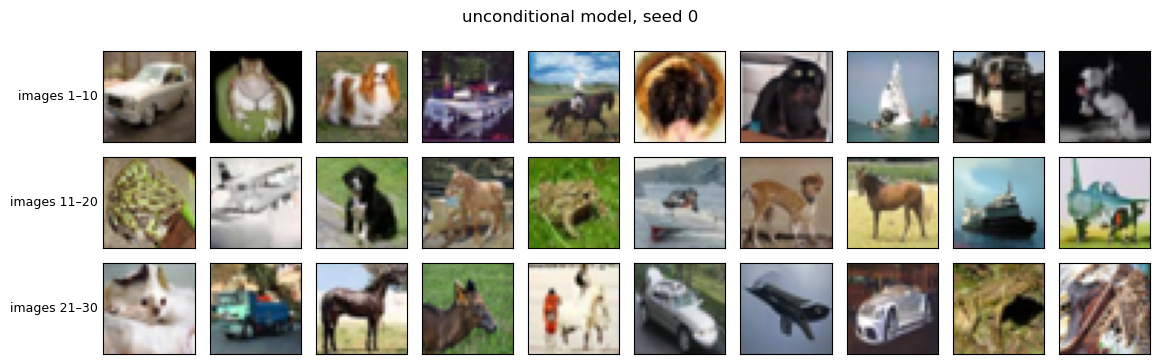

In [4]:
def edm_sample(denoise, n, seed, steps=18, sigma_min=0.002, sigma_max=80.0, rho=7.0, record=False):
    """EDM's deterministic sampler. denoise(x, sigma) returns the clean-image estimate.
    With record=True it also returns, for each step, the noise level σ, the noisy image x and the estimate D(x; σ)."""
    i = torch.arange(steps, dtype=torch.float64)
    sigmas = (sigma_max ** (1 / rho) + i / (steps - 1) * (sigma_min ** (1 / rho) - sigma_max ** (1 / rho))) ** rho
    sigmas = sigmas.tolist() + [0.0]
    x = torch.randn(n, 3, 32, 32, generator=torch.Generator().manual_seed(seed)).to(DEVICE) * sigmas[0]
    history = []
    for s, s_next in zip(sigmas[:-1], sigmas[1:]):
        estimate = denoise(x, s)
        if record:
            history.append((s, x.cpu(), estimate.cpu()))
        d = (x - estimate) / s                               # direction from the clean estimate to x
        x_next = x + (s_next - s) * d                        # Euler step to the next noise level
        if s_next > 0:                                       # Heun: average with the direction there
            x_next = x + (s_next - s) * (d + (x_next - denoise(x_next, s_next)) / s_next) / 2
        x = x_next
    return (x, history) if record else x


@torch.no_grad()
def D(net, x, sigma, labels=None):
    """The clean-image estimate: D(x; σ) if labels is None, else D(x; σ, c) for the class indices in labels."""
    s = torch.full((len(x),), sigma, device=x.device)
    c = None if labels is None else F.one_hot(labels, 10).float().to(x.device)
    return net(x, s, c).float()


x = edm_sample(lambda x, s: D(uncond, x, s), n=30, seed=0)
show_grid({f"images {10 * k + 1}–{10 * k + 10}": to_uint8(x[10 * k:10 * k + 10]) for k in range(3)},
          title="unconditional model, seed 0")

### Inside the sampler: the trajectory and the denoiser's estimates
At each noise level the sampler holds a noisy image $x$ and asks the network for its estimate of the clean image,
$D(x;\sigma)$. The figure follows three images from $\sigma = 80$ down to $\sigma = 0.002$. For each image, the
upper row is the noisy image and the lower row is $D(x;\sigma)$. The noisy image is shown as the course's
$x_t = x/\sqrt{1+\sigma^2}$, which keeps it in the display range.

**Before running:** what will $D(x;\sigma)$ look like at $\sigma = 80$? (In code session 2, the MNIST denoiser's
guess at high noise was an average digit.) At which noise level do you expect the content of the final image to
be settled?

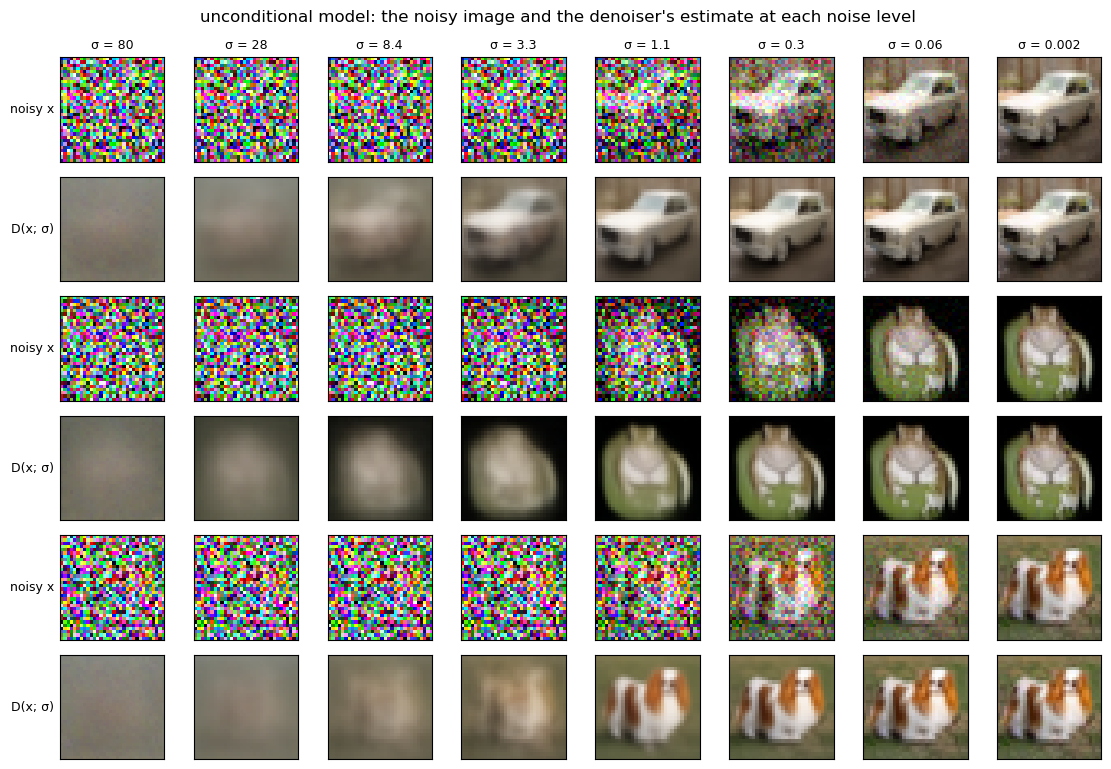

In [5]:
def show_trajectory(history, rows=3, steps=(0, 3, 6, 8, 10, 12, 14, 17), title=None):
    """For the first `rows` images: the noisy image (as x_t) above the estimate D(x; σ), at several steps."""
    fig, axes = plt.subplots(2 * rows, len(steps), figsize=(1.25 * len(steps) + 1.4, 2.6 * rows), squeeze=False)
    for j, k in enumerate(steps):
        s, x, estimate = history[k]
        for i in range(rows):
            axes[2 * i, j].imshow(to_uint8(x[i] / (1 + s ** 2) ** 0.5).permute(1, 2, 0).numpy())
            axes[2 * i + 1, j].imshow(to_uint8(estimate[i]).permute(1, 2, 0).numpy())
        axes[0, j].set_title(f"σ = {s:.2g}", fontsize=9)
    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])
    for i in range(rows):
        axes[2 * i, 0].set_ylabel("noisy x", rotation=0, ha="right", va="center", fontsize=9)
        axes[2 * i + 1, 0].set_ylabel("D(x; σ)", rotation=0, ha="right", va="center", fontsize=9)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    plt.show()


_, history = edm_sample(lambda x, s: D(uncond, x, s), n=3, seed=0, record=True)
show_trajectory(history, title="unconditional model: the noisy image and the denoiser's estimate at each noise level")

## 2. Conditional samples

The conditional model takes the class as a one-hot vector. Each row requests one class, and each column starts
from the same noise. **Before running:** what do you expect to stay the same down a column?

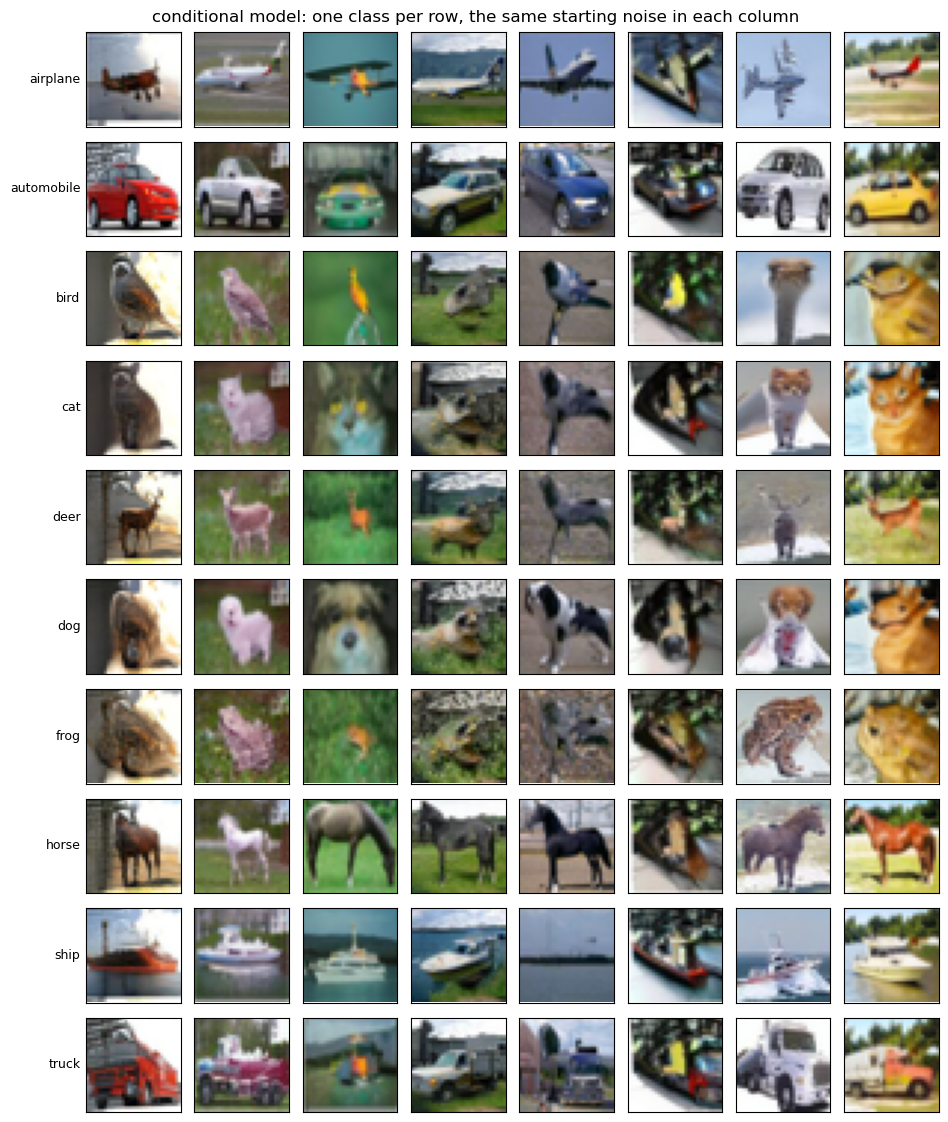

In [6]:
rows = {}
for c in range(10):
    labels = torch.full((8,), c)
    rows[CLASSES[c]] = to_uint8(edm_sample(lambda x, s: D(cond, x, s, labels), n=8, seed=1))
show_grid(rows, title="conditional model: one class per row, the same starting noise in each column")

## 3. CFG with two networks

CFG mixes the two estimates:
$$D_w(x;\sigma,c) = D(x;\sigma) + w\,\big(D(x;\sigma,c) - D(x;\sigma)\big).$$
$w = 0$ gives the unconditional model and $w = 1$ the conditional one; $w > 1$ pushes further along the
difference that the class makes.

On MNIST one network gave both estimates, because it was trained with the label replaced by "no label" (10) 10%
of the time. **EDM's conditional network was trained without that, so it has no "no label" input.** Its code has
the switch, `label_dropout` (printed below), but EDM's `train.py` never turns it on, and the checkpoint records 0.
So here the unconditional estimate comes from the separate unconditional network: CFG with two networks. Both
were trained on the same images with the same architecture and noise levels, so their estimates can be mixed.

In [7]:
source = (EDM_DIR / "training" / "networks.py").read_text().splitlines()
k = next(i for i, line in enumerate(source) if "self.training and self.label_dropout" in line)
print("EDM, training/networks.py, inside SongUNet.forward:")
print("\n".join(source[k - 2:k + 3]))
print("\nlabel_dropout stored in the released conditional network:", cond.model.label_dropout)

EDM, training/networks.py, inside SongUNet.forward:
        if self.map_label is not None:
            tmp = class_labels
            if self.training and self.label_dropout:
                tmp = tmp * (torch.rand([x.shape[0], 1], device=x.device) >= self.label_dropout).to(tmp.dtype)
            emb = emb + self.map_label(tmp * np.sqrt(self.map_label.in_features))

label_dropout stored in the released conditional network: 0


**Before running:** what should change as $w$ goes from 1 to 4?

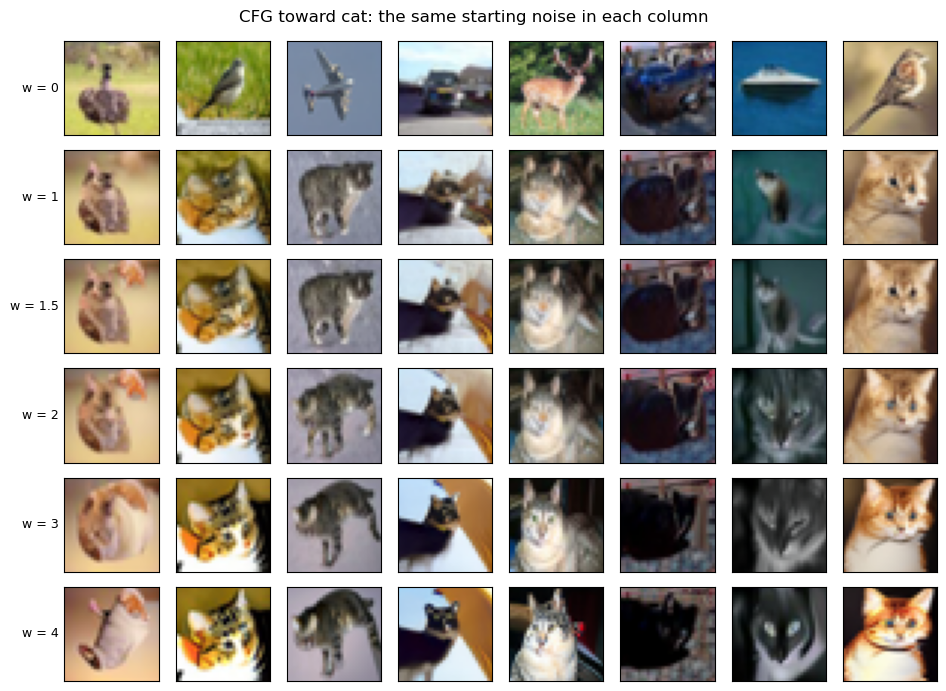

In [8]:
def D_cfg(x, sigma, labels, w):
    """CFG with two networks: D(x; σ) + w (D(x; σ, c) − D(x; σ))."""
    if w == 1:
        return D(cond, x, sigma, labels)                     # one network evaluation instead of two
    d_uncond = D(uncond, x, sigma)
    if w == 0:
        return d_uncond
    return d_uncond + w * (D(cond, x, sigma, labels) - d_uncond)


W = [0, 1, 1.5, 2, 3, 4]
labels = torch.full((8,), CLASSES.index("cat"))
show_grid({f"w = {w:g}": to_uint8(edm_sample(lambda x, s: D_cfg(x, s, labels, w), n=8, seed=2)) for w in W},
          title="CFG toward cat: the same starting noise in each column")

**Your turn: trajectories with a condition.** Make the trajectory figure from part 1 for the conditional model
($w = 1$) and for CFG at $w = 4$, toward one class and from the same seed. `edm_sample(..., record=True)` returns
the images and the history; `show_trajectory(history)` draws it. Then answer in your notes:
1. At which noise level does the class first show in $D(x;\sigma)$? Is it earlier with $w = 4$?
2. From which noise level on does the image barely change?
3. How do the $w = 4$ estimates differ from the $w = 1$ ones at low noise?

In [ ]:
labels = torch.full((3,), CLASSES.index("cat"))   # the same class and seed as the part-3 grid
_, history_w1 = edm_sample(lambda x, s: D(cond, x, s, labels), n=3, seed=2, record=True)
show_trajectory(history_w1, title="conditional model (w = 1) toward cat, seed 2")

_, history_w4 = edm_sample(lambda x, s: D_cfg(x, s, labels, 4.0), n=3, seed=2, record=True)
show_trajectory(history_w4, title="CFG at w = 4 toward cat, seed 2")

### The same trajectory as an animation

The report shows still figures; the animation below animates the $w = 4$ trajectory of the first image: on the
left the noisy image at the current $\sigma$, on the right the denoiser's estimate $D_w(x;\sigma,c)$, one frame
per sampler step. It is saved as a GIF in `outputs/` so it can be linked from the README.

In [ ]:
import matplotlib.animation as animation

def save_trajectory_gif(history, path, i=0, fps=4):
    """One frame per noise level: the noisy image (as x_t) and the estimate D(x; sigma)."""
    frames = [(s, to_uint8(x[i] / (1 + s ** 2) ** 0.5).permute(1, 2, 0).numpy(),
               to_uint8(est[i]).permute(1, 2, 0).numpy()) for s, x, est in history]
    fig, axes = plt.subplots(1, 2, figsize=(4.6, 2.5))
    def draw(k):
        s, x, est = frames[k]
        for ax in axes:
            ax.clear(); ax.set_xticks([]); ax.set_yticks([])
        axes[0].imshow(x)
        axes[1].imshow(est)
        axes[0].set_title(f"noisy x, $\\sigma = {s:.2g}$", fontsize=9)
        axes[1].set_title("$D(x; \\sigma, c)$", fontsize=9)
        fig.tight_layout()
    animation.FuncAnimation(fig, draw, frames=len(frames), interval=1000 // fps).save(
        path, writer=animation.PillowWriter(fps=4))
    plt.close(fig)
    print("saved", path)

save_trajectory_gif(history_w4, OUT / "trajectory_cfg_w4.gif")   # CFG at w = 4 toward cat, seed 2

## 4. Measuring: label accuracy and FID

**Label accuracy** is the fraction of images that a pretrained CIFAR-10 classifier assigns to the requested
class. We use a small ResNet-56 from chenyaofo/pytorch-cifar-models; the cell checks its accuracy on real test
images. The NA-RFM paper uses a ConvNeXt-Tiny; switch to it when you compare with the paper in week 8. The
classifier only scores images. It never guides the sampler.

In [ ]:
class Block(torch.nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.conv1 = torch.nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn1 = torch.nn.BatchNorm2d(cout)
        self.conv2 = torch.nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.bn2 = torch.nn.BatchNorm2d(cout)
        self.downsample = None
        if stride != 1 or cin != cout:
            self.downsample = torch.nn.Sequential(torch.nn.Conv2d(cin, cout, 1, stride, bias=False),
                                                  torch.nn.BatchNorm2d(cout))

    def forward(self, x):
        out = self.bn2(self.conv2(torch.relu(self.bn1(self.conv1(x)))))
        return torch.relu(out + (x if self.downsample is None else self.downsample(x)))


class ResNet56(torch.nn.Module):
    """The CIFAR-10 ResNet-56 of chenyaofo/pytorch-cifar-models, with matching parameter names."""
    def __init__(self):
        super().__init__()
        self.conv1 = torch.nn.Conv2d(3, 16, 3, 1, 1, bias=False)
        self.bn1 = torch.nn.BatchNorm2d(16)
        stage = lambda cin, cout, stride: torch.nn.Sequential(Block(cin, cout, stride),
                                                              *[Block(cout, cout, 1) for _ in range(8)])
        self.layer1, self.layer2, self.layer3 = stage(16, 16, 1), stage(16, 32, 2), stage(32, 64, 2)
        self.fc = torch.nn.Linear(64, 10)

    def forward(self, x):
        x = self.layer3(self.layer2(self.layer1(torch.relu(self.bn1(self.conv1(x))))))
        return self.fc(x.mean((2, 3)))


classifier = ResNet56()
classifier.load_state_dict(torch.load(DL / "cifar10_resnet56-187c023a.pt", map_location="cpu", weights_only=True))
classifier = classifier.to(DEVICE).eval()
MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1)
STD = torch.tensor([0.2023, 0.1994, 0.2010]).view(1, 3, 1, 1)


@torch.no_grad()
def classify(images):
    """The classifier's predicted class for each uint8 image."""
    out = []
    for i in range(0, len(images), 500):
        x = (images[i:i + 500].float() / 255 - MEAN) / STD
        out.append(classifier(x.to(DEVICE)).argmax(1).cpu())
    return torch.cat(out)


n = 1000 if QUICK else 10_000
print(f"classifier accuracy on {n} real test images: {(classify(test_images[:n]) == test_labels[:n]).float().mean():.1%}")

**FID** compares two sets of images in three steps.
1. Run every image through the Inception-v3 network and keep 2048 numbers per image, its *features*.
2. Fit a Gaussian to each set of features: its mean $\mu$ and covariance $\Sigma$. This is the Gaussian fit from
   the PCA slides, now in feature space.
3. Measure the distance between the two Gaussians:
$$\mathrm{FID} = \|\mu_r - \mu_g\|^2 + \mathrm{tr}\big(\Sigma_r + \Sigma_g - 2(\Sigma_r\Sigma_g)^{1/2}\big).$$
The first term grows when the average images differ, the second when their spreads differ, for example when
generated images lack variety. Lower is better, and 0 means identical Gaussians. The reference $(\mu_r,\Sigma_r)$
is EDM's: the statistics of the 50,000 CIFAR-10 training images in `cifar10-32x32.npz`. The detector, the
reference and the formula are the ones EDM's `fid.py` uses.

**FID ignores the labels.** It compares the whole set of generated images with all 50,000 training images, which
come in equal numbers from the ten classes. That suits the unconditional model. It also suits conditional and CFG
runs when the requested classes are balanced, as in part 5 (100 images per class). EDM's paper scores its
conditional model the same way, with random classes against this same reference.

**FID_class** checks each class against its own real images. It computes FID separately for each class, comparing
the images that requested class $c$ with the 5,000 training images of class $c$, and averages over the ten
classes. The NA-RFM paper reports this kind of FID. Part 5 computes both.

In [ ]:
FID_DEVICE = DEVICE if DEVICE.type == "cuda" else torch.device("cpu")   # the detector is slow on Apple GPUs
with open(DL / "inception-2015-12-05.pkl", "rb") as f:
    detector = pickle.load(f).to(FID_DEVICE)
ref = np.load(DL / "cifar10-32x32.npz")
MU_REF, SIGMA_REF = torch.from_numpy(ref["mu"]).double(), torch.from_numpy(ref["sigma"]).double()


@torch.no_grad()
def features(images):
    """Step 1: 2048 Inception features for each uint8 image."""
    return torch.cat([detector(images[i:i + 100].to(FID_DEVICE), return_features=True).double().cpu()
                      for i in range(0, len(images), 100)])


def gaussian(f):
    """Step 2: the mean and covariance of a set of features."""
    return f.mean(0), torch.cov(f.T)


def frechet(mu1, s1, mu2, s2):
    """Step 3: the distance between two Gaussians."""
    e, V = torch.linalg.eigh(s1)
    r = V @ torch.diag(e.clamp(min=0).sqrt()) @ V.T          # Σ1^(1/2)
    m = r @ s2 @ r                                           # has the same eigenvalues as Σ1 Σ2
    root_trace = torch.linalg.eigvalsh((m + m.T) / 2).clamp(min=0).sqrt().sum()   # tr((Σ1 Σ2)^(1/2))
    return float(((mu1 - mu2) ** 2).sum() + s1.trace() + s2.trace() - 2 * root_trace)


def fid(images):
    """FID of uint8 images against the 50,000 CIFAR-10 training images."""
    return frechet(*gaussian(features(images)), MU_REF, SIGMA_REF)

### FID in two dimensions
The same formula works for any number of features. Here the "real" cloud has 100,000 points in 2D, and each panel
compares it with a "generated" cloud. **Before running:** which panel has the largest FID, and which term causes
it?

In [ ]:
g = torch.Generator().manual_seed(0)
A = torch.tensor([[1.0, 0.0], [0.8, 0.5]], dtype=torch.float64)    # gives the cloud its tilted shape


def cloud(n, shift=(0.0, 0.0), spread=1.0):
    return (torch.randn(n, 2, generator=g, dtype=torch.float64) * spread) @ A.T + torch.tensor(shift, dtype=torch.float64)


def ellipse(ax, mu, cov, color):
    """Draw the Gaussian's two-standard-deviation ellipse."""
    e, V = torch.linalg.eigh(cov)
    t = torch.linspace(0, 2 * torch.pi, 200, dtype=torch.float64)
    pts = mu + 2 * torch.stack([t.cos(), t.sin()], 1) @ (V * e.clamp(min=0).sqrt()).T
    ax.plot(pts[:, 0], pts[:, 1], color=color, lw=2)


real = cloud(100_000)
mu_r, s_r = gaussian(real)
cases = {"same distribution, 30 points": cloud(30),
         "shifted mean, 5,000 points": cloud(5000, shift=(1.5, 0.0)),
         "too little variety, 5,000 points": cloud(5000, spread=0.4)}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True, sharey=True)
for ax, (name, pts) in zip(axes, cases.items()):
    mu_g, s_g = gaussian(pts)
    ax.scatter(*real[:3000].T, s=2, color="0.75", label="real")
    ax.scatter(*pts.T, s=14 if len(pts) < 100 else 3, color="tab:orange", label="generated")
    ellipse(ax, mu_r, s_r, "0.3")
    ellipse(ax, mu_g, s_g, "tab:orange")
    total, mean_term = frechet(mu_r, s_r, mu_g, s_g), float(((mu_r - mu_g) ** 2).sum())
    ax.set_title(f"{name}\nFID {total:.2f} = mean term {mean_term:.2f} + spread term {total - mean_term:.2f}",
                 fontsize=10)
axes[0].legend(loc="upper left")
plt.show()

Even the first panel, drawn from the real distribution itself, has FID above 0, because 30 points do not pin
down a Gaussian. **FID gets better (lower) with more samples.**

**We use only 1,000 samples per setting, so our FIDs will be much higher than published ones.** The EDM paper
reports 1.97 (unconditional) and 1.79 (conditional) with 50,000 samples. A high value here does not mean the model
is bad. So:
- **Compare runs only with each other,** at the same number of samples and against the same reference, and report
  the number of samples with every FID.
- **Numbers from other protocols do not compare.** The NA-RFM paper's CIFAR-10 FIDs, around 40, score each class
  separately: its code compares 2,048 generated images with the 6,000 real images of that class, then averages
  over the classes.

## 5. The CFG sweep: accuracy and FID against w

For each $w$ we generate `N_EVAL` images with balanced requests (image $i$ requests class $i \bmod 10$) and
measure both. Image $i$ starts from the same noise for every $w$. At $w = 0$ the request is ignored, so its
accuracy is chance, about 10%; its class histogram below shows what the unconditional model makes.
**Before running:** sketch how you expect accuracy and FID to move as $w$ grows.

In [ ]:
def generate(w, n=N_EVAL):
    """n images with balanced requested classes; saved in outputs/ so that a rerun reuses them."""
    path = OUT / f"cfg_w{w:g}_n{n}.npz"
    if path.exists():
        saved = np.load(path)
        return torch.from_numpy(saved["images"]), torch.from_numpy(saved["labels"])
    labels, images, t0 = torch.arange(n) % 10, [], time.time()
    for b in range(0, n, BATCH):
        lab = labels[b:b + BATCH]
        images.append(to_uint8(edm_sample(lambda x, s: D_cfg(x, s, lab, w), n=len(lab), seed=1000 + b)))
        if b == 0:
            print(f"w = {w:g}: {how_long((time.time() - t0) * n / BATCH)} for {n} images", flush=True)
    images = torch.cat(images)
    np.savez(path, images=images.numpy(), labels=labels.numpy())
    return images, labels


n_ref = 1000 if QUICK else len(train_images)            # real images for FID_class: all 50,000 on a GPU
train_features = features(train_images[:n_ref])
CLASS_REF = [gaussian(train_features[train_labels[:n_ref] == c]) for c in range(10)]


def fid_class(feats, labels):
    """FID of each class's images against the real training images of that class, averaged over the classes."""
    return float(np.mean([frechet(*gaussian(feats[labels == c]), *CLASS_REF[c]) for c in range(10)]))


results = {}
for w in W:
    images, labels = generate(w)
    predicted, feats = classify(images), features(images)
    results[w] = {"accuracy": (predicted == labels).float().mean().item(),
                  "fid": frechet(*gaussian(feats), MU_REF, SIGMA_REF),
                  "fid_class": fid_class(feats, labels) if w > 0 else None}   # w = 0 requests no class
    if w == 0:
        histogram = torch.bincount(predicted, minlength=10)
    per_class = f"{results[w]['fid_class']:7.1f}" if w > 0 else "      –"
    print(f"w = {w:<4g} accuracy {results[w]['accuracy']:6.1%}   FID {results[w]['fid']:7.2f}   "
          f"FID_class {per_class}", flush=True)

(OUT / f"cfg_sweep_n{N_EVAL}.json").write_text(json.dumps(
    {"n_images": N_EVAL, "results": {f"{w:g}": r for w, r in results.items()}}, indent=2))

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(W, [results[w]["accuracy"] for w in W], marker="o")
axes[0, 0].set(xlabel="w", ylabel="label accuracy", title="Does the image show the requested class?")
axes[0, 1].plot(W, [results[w]["fid"] for w in W], marker="o")
axes[0, 1].set(xlabel="w", ylabel=f"FID ({N_EVAL} images, all classes)", title="How close to real images?")
axes[1, 0].plot(W[1:], [results[w]["fid_class"] for w in W[1:]], marker="o", color="tab:green")
axes[1, 0].set(xlabel="w", ylabel=f"FID_class ({N_EVAL // 10} images per class)",
               title="How close to real images of the requested class?")
axes[1, 1].bar(CLASSES, histogram.numpy())
axes[1, 1].set(title="w = 0: classes the unconditional model makes", ylabel="images")
axes[1, 1].tick_params(axis="x", rotation=60)
fig.tight_layout()
plt.show()

These numbers per $w$, with the number of images, are your table for the checkpoint.

**FID over all classes worsens as $w$ grows, and that is expected.** CFG makes the images of each class more alike,
so the whole set has less variety than the 50,000 training images it is compared with. FID_class compares each
class only with real images of that class. With only 100 images per class it is much higher than the all-class
FID (FID gets better with more samples), so compare it across $w$, not with the other FID.

A question for your notes: which $w$ would you choose, and what does each measure miss? Look at the images, not
only the numbers.

## 6. Train EDM's network on a small subset of CIFAR-10, with CFG

You train EDM's network yourself, for CFG, twice: on 100 and on 1,000 CIFAR-10 images. You save snapshots while
it trains and measure each snapshot with FID.

### The switch for CFG: label dropout
You saw EDM's switch in part 3. While training, each one-hot label is multiplied by 0 with probability
`label_dropout`, so for that fraction of examples the network sees "no label" (all zeros). It learns
$D(x;\sigma,c)$ and $D(x;\sigma)$ at once. Given no label it is an unconditional model; given a label it is a
conditional model. So CFG needs only this one network, as on MNIST. Here `label_dropout` is 0.1.

### Alert: with few training images the model memorizes
**What memorization means.** The network learns to estimate the clean image from a noisy one. For a fixed set of
training images, the best possible estimate is a weighted average of those images, where each image is weighted by
how likely it is to have produced the noisy image.
- At high noise all the weights are similar, so the estimate is close to the average image: the gray blur in part
  1's trajectory figure.
- At low noise one training image takes almost all the weight, so a sampler that follows this estimate ends on a
  copy of that training image.

A network that learns this estimate exactly has **memorized** its training images: its samples are copies, not
new images. With 100 or 1,000 images that is easy, so these runs memorize. With many training images the network
cannot fit each one exactly. It learns a smoother estimate and makes new images, which is called
**generalization**.

So these runs **test your training pipeline end to end**: the loss goes down and the samples come to match
training images. Watch what FID does across the snapshots, and explain it. To see a model make new images, train
on all the data: the encouraged run at the end of this part.

The network is a smaller version of EDM's CIFAR-10 network (7.0M parameters instead of 55.7M), so that a run
fits in a notebook. Training uses EDM's loss, `EDMLoss`: add noise at a random level $\sigma$ to a training
image, and penalize the squared error of the network's clean-image estimate, with EDM's weighting over noise
levels. Each snapshot is measured with FID on unconditional samples (no label), against the full CIFAR-10
reference, at a fixed number of images.

In [ ]:
SIZES = [100, 1000]          # the two training sets, balanced over the classes
STEPS = int(os.environ.get("LAB_STEPS", 500 if QUICK else 20_000))   # updates per training set
SNAPSHOTS = 2 if QUICK else 5    # evenly spaced snapshots per run; each is saved and measured with FID
N_SNAPSHOT = 100 if QUICK else 1000   # unconditional samples per snapshot for FID
BATCH_TRAIN = 64
LABEL_DROPOUT = 0.1          # the CFG switch: 10% of training labels become "no label"


def subset(n):
    """The first n // 10 training images of each class: images in [-1, 1], labels, and their indices."""
    idx = torch.cat([torch.nonzero(train_labels == c).flatten()[:n // 10] for c in range(10)])
    return train_images[idx].float() / 127.5 - 1, train_labels[idx], idx


def D_own(net, x, sigma, labels, w):
    """CFG with one network: D(x; σ) with no label, plus w times the difference the label makes."""
    d_uncond = D(net, x, sigma)
    if w == 0:
        return d_uncond
    return d_uncond + w * (D(net, x, sigma, labels) - d_uncond)


def own_samples(net, n, w=0, seed=10):
    """n uint8 samples requesting class i mod 10 for image i; w = 0 ignores the request (no label)."""
    labels, out = torch.arange(n) % 10, []
    for b in range(0, n, 500):
        lab = labels[b:b + 500]
        out.append(to_uint8(edm_sample(lambda x, s: D_own(net, x, s, lab, w), n=len(lab), seed=seed + b)))
    return torch.cat(out), labels


def train(n_train):
    """Train a CFG network on n_train images; save and measure a snapshot every STEPS // SNAPSHOTS updates."""
    x_train, y_train, _ = subset(n_train)
    torch.manual_seed(0)
    net = EDMPrecond(img_resolution=32, img_channels=3, label_dim=10, model_type="SongUNet",
                     label_dropout=LABEL_DROPOUT,
                     model_channels=64, channel_mult=[1, 2, 2], num_blocks=2,   # EDM's own: 128, [2, 2, 2], 4
                     attn_resolutions=[16], dropout=0.0, embedding_type="positional", encoder_type="standard",
                     decoder_type="standard", channel_mult_noise=1, resample_filter=[1, 1]).to(DEVICE).train()
    ema = copy.deepcopy(net).eval().requires_grad_(False)       # averaged weights, used for sampling
    opt = torch.optim.Adam(net.parameters(), lr=2e-4)
    loss_fn, gen = EDMLoss(), torch.Generator().manual_seed(0)
    losses, fids, progress, t0 = [], {}, {}, time.time()
    for step in range(1, STEPS + 1):
        batch = torch.randint(len(x_train), (BATCH_TRAIN,), generator=gen)
        labels = F.one_hot(y_train[batch], 10).float().to(DEVICE)   # the network drops 10% of these while training
        loss = loss_fn(net, x_train[batch].to(DEVICE), labels).mean()
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        with torch.no_grad():
            decay = 0.9 if step <= 1000 else 0.999              # the course's EMA, with its warm-up
            for p_ema, p in zip(ema.parameters(), net.parameters()):
                p_ema.lerp_(p, 1 - decay)
        losses.append(loss.item())
        if step == 100:
            print(f"{n_train} images: {how_long((time.time() - t0) / 100 * STEPS)} for {STEPS} updates, "
                  f"plus FID at each snapshot", flush=True)
        if step % (STEPS // SNAPSHOTS) == 0:                    # a snapshot
            torch.save(ema.state_dict(), OUT / f"subset{n_train}_update{step}.pt")
            images = own_samples(ema, N_SNAPSHOT)[0]
            fids[step], progress[step] = fid(images), images[:10]
            print(f"{n_train} images, update {step}: loss {np.mean(losses[-500:]):.3f}, FID {fids[step]:.1f}, "
                  f"{how_long(time.time() - t0)} so far", flush=True)
    return {"net": ema, "losses": losses, "fids": fids, "progress": progress}


runs = {n: train(n) for n in SIZES}

### Loss and FID across snapshots
Each update draws new noise levels, some easy and some hard, so the loss jumps from update to update; the plot
averages it. The loss also flattens early while the samples keep improving, so judge training by the samples and
by FID across snapshots, not by the loss alone. EDM's own `train.py` writes its loss as `"Loss/loss"` in
`stats.jsonl` in the run folder; the commented lines plot it.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for n, run in runs.items():
    k = min(200, len(run["losses"]))
    axes[0].plot(range(k - 1, len(run["losses"])), np.convolve(run["losses"], np.ones(k) / k, mode="valid"),
                 label=f"{n} training images")
    axes[1].plot(list(run["fids"]), list(run["fids"].values()), marker="o", label=f"{n} training images")
axes[0].set(yscale="log", xlabel="update", ylabel=f"loss, average of {k} updates", title="Training loss")
axes[1].set(xlabel="update", ylabel=f"FID ({N_SNAPSHOT} unconditional samples)", title="FID across snapshots")
axes[0].legend()
axes[1].legend()
fig.tight_layout()
plt.show()
for n, run in runs.items():
    show_grid({f"update {s}": images for s, images in run["progress"].items()},
              title=f"{n} training images: unconditional samples from the same noise at each snapshot")

# For a run of EDM's train.py:
# rows = [json.loads(line) for line in open("training-runs/00000-.../stats.jsonl")]
# plt.plot([r["Progress/kimg"]["mean"] for r in rows], [r["Loss/loss"]["mean"] for r in rows])

### Is it memorization? Nearest training images
For each sample from the last snapshot, find the closest training image in pixels, and do the same for real test
images, which are new images by definition. If the samples sit much closer to the training images than the test
images do, the model has memorized its training images. (Optional: draw `show_trajectory` for your network. How
early does $D(x;\sigma)$ lock onto one training image?)

In [ ]:
def nearest(images, x_train):
    """Distance to, and index of, the nearest training image, in pixels scaled to [-1, 1]."""
    return torch.cdist(images.float().flatten(1) / 127.5 - 1, x_train.flatten(1)).min(1)


for n, run in runs.items():
    x_train, _, idx = subset(n)
    samples = own_samples(run["net"], 100, seed=20)[0]
    d_gen, i_gen = nearest(samples, x_train)
    d_test, _ = nearest(test_images[:100], x_train)
    print(f"{n} training images, median distance to the nearest training image: "
          f"samples {d_gen.median():.1f}, real test images {d_test.median():.1f}")
    show_grid({"sample": samples[:10], "nearest training image": train_images[idx][i_gen[:10]]},
              title=f"{n} training images, last snapshot")

### The effect of CFG with your network
Now one network gives both estimates: $D(x;\sigma)$ with no label and $D(x;\sigma,c)$ with the label.
**Before running:** does $w > 1$ raise label accuracy here? Compare with part 5.

In [ ]:
for n, run in runs.items():
    rows = {}
    for w in [0, 1, 2, 4]:
        x, labels = own_samples(run["net"], 100, w=w, seed=30)
        rows[f"w = {w}, accuracy {(classify(x) == labels).float().mean():.0%}"] = x[:10]
    show_grid(rows, title=f"{n} training images: CFG with one network, the same starting noise in each column")

### Encouraged for your checkpoint: an actual training run
The runs above memorize. To see real training, and to make use of your GPU time, train EDM's full CIFAR-10
network on all 50,000 images with EDM's own `train.py`. This is the same 55.7M-parameter network as the pretrained
model in parts 1–5. Run it on a DSMLP GPU for as many hours as you can. EDM's full schedule, 200 million training
images, took about two days on 8 V100 GPUs, so a few hours on one GPU covers a small part of it. Expect FID to
keep falling but to stay above the pretrained model's. In your checkpoint report, show the loss curve and FID
across snapshots.

The next cell writes CIFAR-10 in EDM's dataset format, the zip of PNG files that `dataset_tool.py` makes, and
prints the command to start training. Run that command in a terminal, or as a background job, not in this
notebook. `train.py` needs the packages in EDM's `environment.yml`, such as `click` and `psutil`. With PyTorch
2.2 or later it also needs a one-line fix, which this notebook applies to its own copy of EDM: in
`torch_utils/misc.py`, `super().__init__(dataset)` becomes `super().__init__()`. It prints its
progress at every tick (50,000 training images), saves a `network-snapshot-*.pkl` every 10 ticks, and writes its
loss to `stats.jsonl`. A run can be stopped at any time; `--resume` continues from a saved `training-state-*.pt`.

In [ ]:
def export_edm_dataset(n=50_000):
    """Write the first n training images in EDM's dataset format: the zip of PNGs that dataset_tool.py makes."""
    from PIL import Image
    path, labels = (OUT / f"cifar10-32x32-n{n}.zip").resolve(), []
    with zipfile.ZipFile(path, "w", zipfile.ZIP_STORED) as z:
        for i in range(n):
            name = f"{i // 1000:05d}/img{i:08d}.png"
            png = io.BytesIO()
            Image.fromarray(train_images[i].permute(1, 2, 0).numpy()).save(png, format="png", compress_level=0)
            z.writestr(name, png.getvalue())
            labels.append([name, int(train_labels[i])])
        z.writestr("dataset.json", json.dumps({"labels": labels}))
    return path


data = export_edm_dataset()
print("In a terminal:")
print(f"  cd {EDM_DIR.resolve()}")
print(f"  torchrun --standalone --nproc_per_node=1 train.py --outdir=training-runs --data={data} --cond=0 "
      f"--arch=ddpmpp --batch=512 --batch-gpu=64 --duration=10 --snap=10")

`--duration=10` stops after 10 million training images, but you can stop sooner. Each run writes a folder such as
`training-runs/00000-cifar10-32x32-n50000-uncond-ddpmpp-edm-gpus1-batch512-fp32`. Once it holds a few snapshots,
set `RUN_DIR` to that folder and run the next cell. It plots the loss from `stats.jsonl`, and FID on 1,000
unconditional samples from each snapshot.

In [ ]:
RUN_DIR = None   # for example EDM_DIR / "training-runs" / "00000-cifar10-32x32-n50000-uncond-ddpmpp-edm-gpus1-batch512-fp32"

if RUN_DIR is not None:
    run_dir = Path(RUN_DIR)
    rows = [json.loads(line) for line in open(run_dir / "stats.jsonl")]
    snapshot_fid = {}
    for path in sorted(run_dir.glob("network-snapshot-*.pkl")):
        with open(path, "rb") as f:
            snap = pickle.load(f)["ema"].to(DEVICE).eval().requires_grad_(False)
        images = torch.cat([to_uint8(edm_sample(lambda x, s: D(snap, x, s), n=min(BATCH, 1000 - b), seed=3000 + b))
                            for b in range(0, 1000, BATCH)])
        mimg = int(path.stem.split("-")[-1]) / 1000              # million training images seen
        snapshot_fid[mimg] = fid(images)
        print(f"{path.name}: FID {snapshot_fid[mimg]:.1f}", flush=True)
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    axes[0].plot([r["Progress/kimg"]["mean"] / 1000 for r in rows], [r["Loss/loss"]["mean"] for r in rows])
    axes[0].set(xlabel="million training images", ylabel="loss", title="Training loss, from stats.jsonl")
    axes[1].plot(list(snapshot_fid), list(snapshot_fid.values()), marker="o")
    axes[1].set(xlabel="million training images", ylabel="FID (1,000 samples)", title="FID across snapshots")
    fig.tight_layout()
    plt.show()

### Optional
- **A CFG network with `train.py`.** `train.py` has no option for label dropout. Add
  `c.network_kwargs.update(label_dropout=0.1)` after the `--arch` settings in `train.py`, then train with
  `--cond=1` and test CFG as in part 6.
- **More data in part 6.** Set `SIZES` to `[5000]` or `[10000]` and raise `STEPS`. As the data grows, samples
  should move away from their nearest training images.

That is the whole notebook. What to submit is in the assignment box at the top.